# ĐÁNH GIÁ THỰC NGHIỆM HỆ THỐNG TRINH THÁM NEURO-SYMBOLIC

**Đề tài:** Nghiên cứu và xây dựng trò chơi trinh thám giải đố trên nền tảng Web, ứng dụng mô hình ngôn ngữ lớn (LLM) để sinh tự động các bộ hồ sơ vụ án có tính logic và nhất quán *(Hướng tiếp cận Neuro-Symbolic kết hợp Hệ đa tác tử và Bộ kiểm định hình thức)*.

### Nội dung kiểm chứng trong Notebook:
1. **Cell 1:** Khởi tạo môi trường và nạp các mô-đun từ `detective-backend/`.
2. **Cell 2:** Tổng hợp 30 phiên thử nghiệm lịch sử từ `benchmark_results.json` & SQLite `detective.db` (đối chiếu Bảng 4.1).
3. **Cell 3:** Kiểm chứng giải thuật chia đôi phương trình nhiệt học Henssge (`solve_pmi_bisection`) và phát hiện lỗi tham chiếu `SCHEMA_ERROR`.
4. **Cell 4:** Kiểm thử trực tiếp cơ chế **Smart Per-Agent Fallback** (báo rõ tên mô hình dự phòng cho từng Agent và xác nhận hồ sơ vẫn đạt chuẩn logic).
5. **Cell 5:** Trực quan hóa biểu đồ Tỷ lệ Hợp lệ và Phân bố Độ trễ (đơn vị giây `s`).

In [1]:
import os
import sys
import json
import time
import logging
import statistics
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Gắn đường dẫn tới thư mục backend để chạy trực tiếp từ thư mục gốc
ROOT_DIR = os.path.abspath(".")
BACKEND_DIR = os.path.join(ROOT_DIR, "detective-backend") if os.path.isdir(os.path.join(ROOT_DIR, "detective-backend")) else ROOT_DIR
if BACKEND_DIR not in sys.path:
    sys.path.insert(0, BACKEND_DIR)

import agents
from models import CaseDossier
from validator import solve_pmi_bisection, apply_henssge_tod_window, validate_case_diagnostics
from llm_service import CaseGeneratorService
from database import init_db, SessionLocal, BenchmarkRunRecord
from benchmark_runner import evaluate_single_trial, calc_percentile, format_fallback_report

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
logging.getLogger("httpx").setLevel(logging.WARNING)

print(f"Python: {sys.version.split()[0]} | Backend dir: {BACKEND_DIR}")

Python: 3.13.13 | Backend dir: d:\Work\Đồ Án Tốt Nghiệp\detective-backend


In [2]:
# Tải dữ liệu 30 phiên thực nghiệm từ benchmark_results.json và đối chiếu bảng SQLite benchmark_runs
results_path = os.path.join(BACKEND_DIR, "benchmark_results.json")
with open(results_path, "r", encoding="utf-8") as f:
    raw_trials = json.load(f)

init_db()
with SessionLocal() as db:
    db_count = db.query(BenchmarkRunRecord).count()

df_30 = pd.DataFrame(raw_trials)
models_order = ["gh/gpt-4o-mini", "gh/gpt-4o", "ollama/gemma4:31b-cloud"]

summary_rows = []
for m in models_order:
    sub = df_30[df_30["model"] == m]
    lats = sub["latency_sec"].tolist()
    summary_rows.append({
        "Model": m,
        "Trials": len(sub),
        "Schema_Valid_%": round(sub["json_valid"].mean() * 100, 1),
        "Logic_Pass_%": round(sub["logic_valid"].mean() * 100, 1),
        "Patch_TB": round(sub["patch_retries"].mean(), 2),
        "P50_s": round(statistics.median(lats), 2),
        "P95_s": round(calc_percentile(lats, 0.95), 2),
        "Crucial/Herring": f"{sub['crucial_clues_count'].mean():.1f} / {sub['red_herrings_count'].mean():.1f}",
    })

df_summary = pd.DataFrame(summary_rows)
print(f"Tổng số phiên trong benchmark_results.json: {len(df_30)} | Số bản ghi trong SQLite benchmark_runs: {db_count}\n")
print("=== BẢNG TỔNG HỢP 30 PHIÊN THỰC NGHIỆM (BẢNG 4.1) ===")
display(df_summary)

failed_cases = df_30[~df_30["logic_valid"]]
if not failed_cases.empty:
    print("\n=== CA VI PHẠM ĐƯỢC BỘ KIỂM ĐỊNH CHẶN LỌC ===")
    for _, row in failed_cases.iterrows():
        print(f"Model: {row['model']} | Trial #{row['trial']} | Latency: {row['latency_sec']}s | Violations: {row['violation_types']}")
        print(f"Diagnostic: {row['error']}")

Tổng số phiên trong benchmark_results.json: 30 | Số bản ghi trong SQLite benchmark_runs: 30

=== BẢNG TỔNG HỢP 30 PHIÊN THỰC NGHIỆM (BẢNG 4.1) ===


,Model,Trials,Schema_Valid_%,Logic_Pass_%,Patch_TB,P50_s,P95_s,Crucial/Herring
0,gh/gpt-4o-mini,10,100.0,100.0,0.0,10.88,12.84,1.0 / 1.0
1,gh/gpt-4o,10,100.0,90.0,0.1,19.53,27.12,1.1 / 1.0
2,ollama/gemma4:31b-cloud,10,100.0,100.0,0.0,10.73,19.92,1.1 / 1.0



=== CA VI PHẠM ĐƯỢC BỘ KIỂM ĐỊNH CHẶN LỌC ===
Model: gh/gpt-4o | Trial #5 | Latency: 27.12s | Violations: ['schema_error']
Diagnostic: [CLUE:schema_error] Evidence 'EV-03' links to non-existent suspect 'UNKNOWN'.


In [3]:
# Kiểm chứng Bộ giải chia đôi phương trình nhiệt học Henssge và Bộ kiểm định đồ thị hai phía
sample_case = CaseGeneratorService.get_sample_case()
f_data = sample_case.victim.forensic_data

t_star = solve_pmi_bisection(
    body_temp=f_data.body_temp,
    ambient_temp=f_data.ambient_temp,
    body_weight_kg=f_data.body_weight_kg,
    cooling_factor=f_data.cooling_factor,
)
apply_henssge_tod_window(f_data)

print(f"Hồ sơ mẫu: {sample_case.case_id} - {sample_case.title}")
print(f"Thông số Henssge: T_body={f_data.body_temp}°C, T_ambient={f_data.ambient_temp}°C, M={f_data.body_weight_kg}kg, C={f_data.cooling_factor}, discovery={f_data.discovery_time}")
print(f"Nghiệm chia đôi PMI: t* = {t_star:.2f} giờ -> Cửa sổ TOD khóa cứng: [{f_data.estimated_tod_start} - {f_data.estimated_tod_end}]")

diag_clean = validate_case_diagnostics(sample_case)
print(f"Kiểm định hồ sơ gốc -> is_valid={diag_clean.is_valid}, violations={len(diag_clean.violations)}")

# Mô phỏng lỗi ảo giác tham chiếu thực thể tương tự Lượt 5 của gh/gpt-4o
corrupted_case = sample_case.model_copy(deep=True)
corrupted_case.evidences[2].linked_suspect_id = "UNKNOWN"
diag_corrupted = validate_case_diagnostics(corrupted_case)
print(f"Kiểm định khi gán EV-03 -> 'UNKNOWN' -> is_valid={diag_corrupted.is_valid}")
for v in diag_corrupted.violations:
    print(f"  [CHẶN LỌC] component={v.component} | type={v.violation_type.value} | msg={v.message}")

Hồ sơ mẫu: CASE-2026-001 - Bí ẩn Biệt thự Blackwood
Thông số Henssge: T_body=31.2°C, T_ambient=21.0°C, M=70.0kg, C=1.0, discovery=08:30
Nghiệm chia đôi PMI: t* = 10.90 giờ -> Cửa sổ TOD khóa cứng: [20:06 - 23:06]
Kiểm định hồ sơ gốc -> is_valid=True, violations=0
Kiểm định khi gán EV-03 -> 'UNKNOWN' -> is_valid=False
  [CHẶN LỌC] component=clue | type=schema_error | msg=Evidence 'EV-03' links to non-existent suspect 'UNKNOWN'.


In [4]:
# Kiểm thử Live Pipeline & Smart Per-Agent Fallback (hiển thị tên model thực tế cho từng Agent)
from openai import AsyncOpenAI

# Giới hạn timeout ngắn (15s, max_retries=0) trong phiên demo Notebook để chuyển mạch nhanh nếu model cloud nghẽn
_orig_async_openai = agents.AsyncOpenAI
def _fast_failover_client(*args, **kwargs):
    kwargs.setdefault("timeout", 15.0)
    kwargs.setdefault("max_retries", 0)
    return _orig_async_openai(*args, **kwargs)

agents.AsyncOpenAI = _fast_failover_client
try:
    test_service = CaseGeneratorService(model="ollama/gemma4:31b-cloud")
    test_service.client = _fast_failover_client(base_url=test_service.api_base, api_key=test_service.api_key)
    for ag in (test_service.outline_agent, test_service.character_agent, test_service.clue_agent, test_service.deduction_agent):
        ag.client = test_service.client

    live_res = await evaluate_single_trial(test_service, theme="Án mạng phòng kín tại Thư viện Cổ Hà Nội")
finally:
    agents.AsyncOpenAI = _orig_async_openai

print(f"Tiêu đề sinh ra : {live_res['title']}")
print(f"Trạng thái JSON  : {live_res['json_valid']} | Hợp lệ Logic: {live_res['logic_valid']}")
print(f"Fallback kích hoạt: {live_res['fallback_triggered']} | Patch retries: {live_res['patch_retries']} | Độ trễ: {live_res['latency_sec']}s")
print(f"Model thực tế theo từng Agent: {json.dumps(live_res['agent_models'], ensure_ascii=False)}")
if live_res['fallback_triggered']:
    print(format_fallback_report("ollama/gemma4:31b-cloud", live_res["agent_models"]).strip(" |"))

[OutlineAgent] Primary model 'ollama/gemma4:31b-cloud' failed (Connection error.). Initiating fallback chain...
[OutlineAgent] Fallback model 'gemini/gemma-4-31b-it' failed (Request timed out.).
[OutlineAgent] Fallback activated: 'ollama/gemma4:31b-cloud' -> 'gh/gpt-3.5-turbo-0613'
[CharacterAgent] Primary model 'ollama/gemma4:31b-cloud' failed (Connection error.). Initiating fallback chain...
[CharacterAgent] Fallback model 'gemini/gemma-4-31b-it' failed (Request timed out.).
[CharacterAgent] Fallback activated: 'ollama/gemma4:31b-cloud' -> 'gh/gpt-3.5-turbo-0613'
[ClueAgent] Primary model 'ollama/gemma4:31b-cloud' failed (Connection error.). Initiating fallback chain...
[ClueAgent] Fallback model 'gemini/gemma-4-31b-it' failed (Request timed out.).
[ClueAgent] Fallback activated: 'ollama/gemma4:31b-cloud' -> 'gh/gpt-3.5-turbo-0613'
[DeductionAgent] Primary model 'ollama/gemma4:31b-cloud' failed (Connection error.). Initiating fallback chain...
[DeductionAgent] Fallback model 'gemini/

Tiêu đề sinh ra : Án mạng bí ẩn tại Thư viện Cổ Hà Nội
Trạng thái JSON  : True | Hợp lệ Logic: True
Fallback kích hoạt: True | Patch retries: 0 | Độ trễ: 76.58s
Model thực tế theo từng Agent: {"OutlineAgent": "gh/gpt-3.5-turbo-0613", "CharacterAgent": "gh/gpt-3.5-turbo-0613", "ClueAgent": "gh/gpt-3.5-turbo-0613", "DeductionAgent": "gh/gpt-3.5-turbo-0613"}
⚠ Fallback lõi 4 Agent -> gh/gpt-3.5-turbo-0613


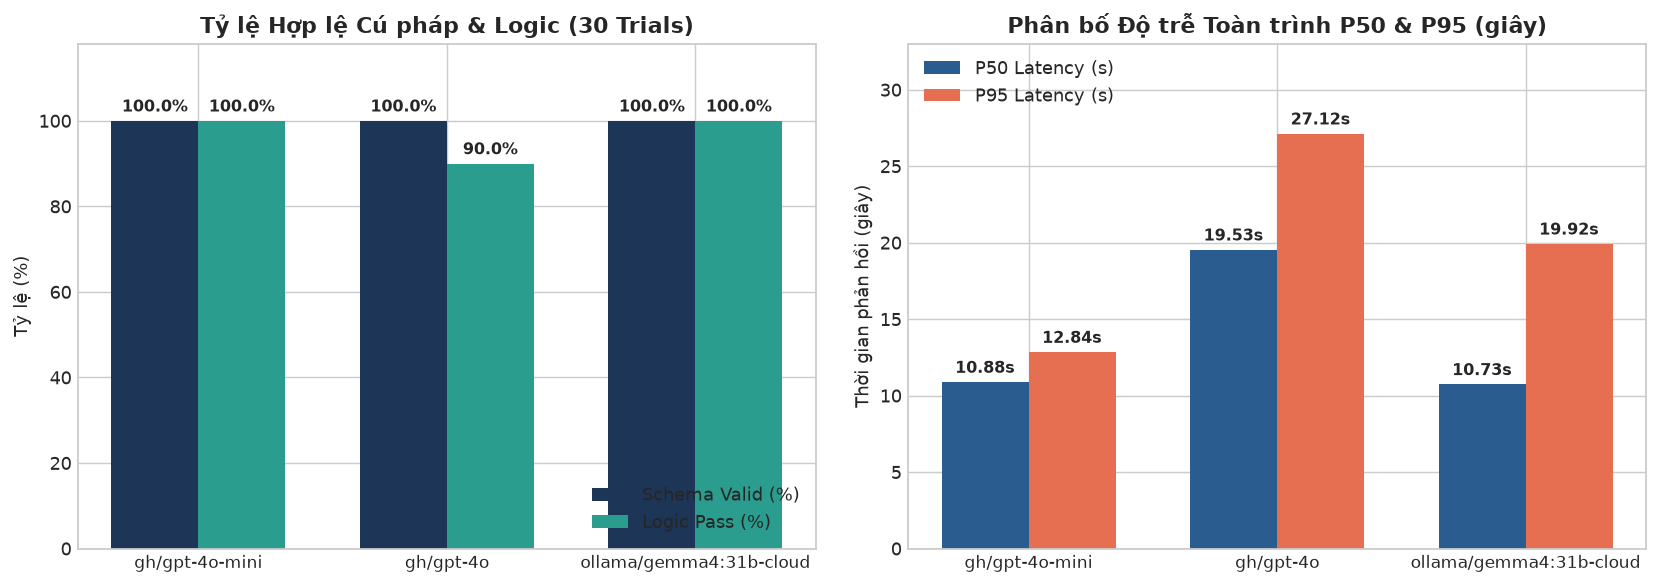

In [5]:
# Trực quan hóa Kết quả Đối sánh 30 Phiên Thực nghiệm (Pass Rate & Latency P50/P95)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), dpi=130)

x = np.arange(len(df_summary))
w = 0.35
labels = df_summary["Model"].tolist()

# Biểu đồ 1: Schema & Logic Pass Rate (%)
b1 = ax1.bar(x - w/2, df_summary["Schema_Valid_%"], w, label="Schema Valid (%)", color="#1D3557")
b2 = ax1.bar(x + w/2, df_summary["Logic_Pass_%"], w, label="Logic Pass (%)", color="#2A9D8F")
ax1.set_title("Tỷ lệ Hợp lệ Cú pháp & Logic (30 Trials)", fontweight="bold")
ax1.set_ylabel("Tỷ lệ (%)")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=9.5)
ax1.set_ylim(0, 118)
ax1.legend(loc="lower right")
for rect in list(b1) + list(b2):
    h = rect.get_height()
    ax1.annotate(f"{h:.1f}%", (rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

# Biểu đồ 2: Độ trễ P50 vs P95 (đơn vị giây s)
l1 = ax2.bar(x - w/2, df_summary["P50_s"], w, label="P50 Latency (s)", color="#2B5C8F")
l2 = ax2.bar(x + w/2, df_summary["P95_s"], w, label="P95 Latency (s)", color="#E76F51")
ax2.set_title("Phân bố Độ trễ Toàn trình P50 & P95 (giây)", fontweight="bold")
ax2.set_ylabel("Thời gian phản hồi (giây)")
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=9.5)
ax2.set_ylim(0, 33)
ax2.legend(loc="upper left")
for rect in list(l1) + list(l2):
    h = rect.get_height()
    ax2.annotate(f"{h:.2f}s", (rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()